In [47]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [62]:
data = pd.read_csv("HappinessAlcoholConsumption.csv", usecols=["Country","Beer_PerCapita","HappinessScore"])

In [63]:
data

,Country,HappinessScore,Beer_PerCapita
0,Denmark,7.526,224
1,Switzerland,7.509,185
2,Iceland,7.501,233
3,Norway,7.498,169
4,Finland,7.413,263
...,...,...,...
117,Tanzania,3.666,36
118,Liberia,3.622,19
119,Benin,3.484,34
120,Togo,3.303,36


In [64]:
new_data = data[["Beer_PerCapita","HappinessScore"]]
new_data.head()

,Beer_PerCapita,HappinessScore
0,224,7.526
1,185,7.509
2,233,7.501
3,169,7.498
4,263,7.413


In [65]:
data_matrix = np.array(new_data)
print(data_matrix[0:4,:])

data_matrix.shape    #dimensions of the numpy array

[[224.      7.526]
 [185.      7.509]
 [233.      7.501]
 [169.      7.498]]


(122, 2)

In [66]:
x_data = data_matrix[:,0]
y_data = data_matrix[:,1] 

Feature Normalisation -It is one of the important step for many ML models , what we actually do is compressing all our input variable in to smaller and similar magnitude so that later computation will be faster and efficient . Below we have one of the feature normalisation technique to make the input variable x in similar magnitude .

In [67]:
x_data = x_data / np.max(x_data)

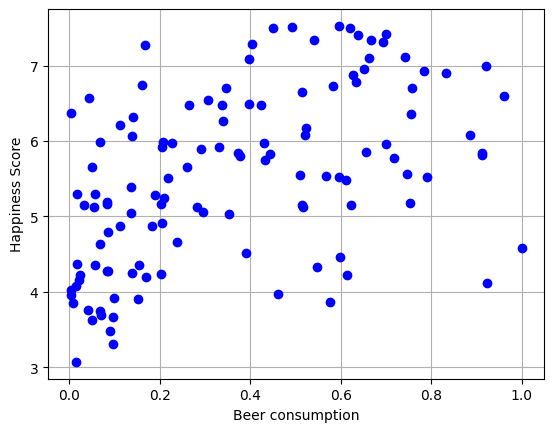

In [72]:
plt.plot(x_data,y_data,'bo')
plt.ylabel('Happiness Score')
plt.xlabel('Beer consumption')
plt.grid()
plt.show()

In [88]:
#initialising parameter
m = np.size(y_data)
x_data = x_data.reshape([122,1])
print(x_data.shape)
theta = np.zeros([2,1])
x = np.hstack([np.ones_like(x_data),x_data])


(122, 1)


In [83]:
print(theta)
print("m: ")
print(m)

[[0.]
 [0.]]
m: 
122


In [118]:
result = x@theta
print(x.shape)
print(theta.shape)
print(result.shape)

(122, 2)
(2, 1)
(122, 1)


In [119]:
def cost_function(x_data,y_data,theta):
    
    j = (1/(2*m)) * np.sum( ((x_data@theta)-y_data)**2 )  # @ means dot-product
    
    return j


cost_function(x,y_data,theta)

189.85032352109056

[[222.65190108]
 [222.66063429]
 [222.66936778]
 ...
 [450.73158314]
 [450.74566158]
 [450.75974029]]


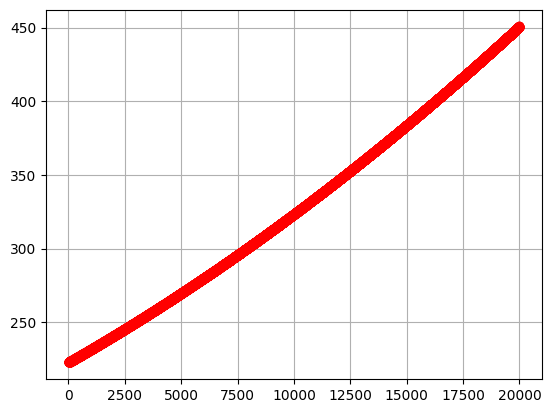

In [123]:
def gradient(x,y,theta):
    
    alpha = 0.00001
    iteration = 20000
#gradient descend algorithm
    J_history = np.zeros([iteration, 1]);
    for iter in range(0,20000):
        error = (x @ theta) -y    # list of 122 values
        # temporal values for computing the new theta
        temp0 = theta[0] - ((alpha/m) * np.sum(error*x[:,0]))
        temp1 = theta[1] - ((alpha/m) * np.sum(error*x[:,1]))
        theta = np.array([temp0,temp1]).reshape(2,1)
        J_history[iter] = (1 / (2*m) ) * (np.sum(((x @ theta)-y)**2))   #compute J value for each iteration 
    return theta, J_history

theta , J = gradient(x,y_data,theta)

print(J)
plt.plot(np.arange(1,20001),J,'ro')
plt.grid()
plt.show()

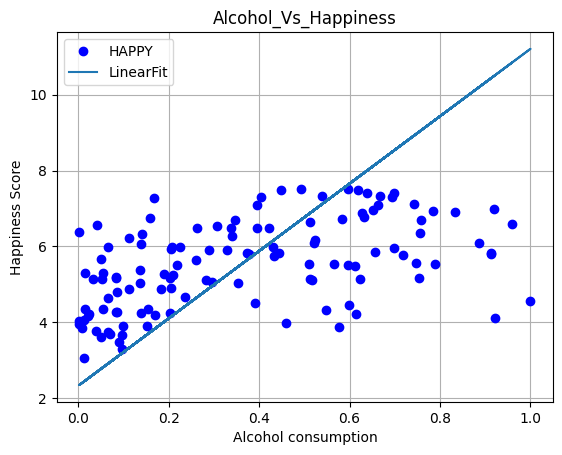

In [125]:
#plot linear fit for our theta
plt.plot(x_data,y_data,'bo')
plt.plot(x_data,x@theta,'-')
plt.ylabel('Happiness Score')
plt.xlabel('Alcohol consumption')
plt.legend(['HAPPY','LinearFit'])
plt.title('Alcohol_Vs_Happiness')
plt.grid()
plt.show()